# 01 – Récupération et préparation des données

Zone d'étude : plateau de Saclay et sud-ouest de l'Île-de-France (≈ 40 × 37 km).
Objectif : obtenir des images Sentinel-2 comparables pour 2017, 2021 et 2025, et une carte de labels pour entraîner le UNet.

Données utilisées :
- **Sentinel-2 L2A**, bandes B02, B03, B04, B08 (bleu, vert, rouge, PIR) à 10 m
- **ESA WorldCover 2021** comme labels (seule année avec image + labels → année d'entraînement)

Accès via le STAC du Microsoft Planetary Computer, sans compte.

In [10]:
# Installation (une seule fois)
%pip install pystac-client planetary-computer odc-stac rioxarray dask

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration

In [11]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import xarray as xr
import rioxarray  # active l'accesseur .rio sur les DataArray
import rasterio
import pystac_client
import planetary_computer
from odc.stac import load as stac_load

DATA_DIR = Path("data_saclay")
DATA_DIR.mkdir(exist_ok=True)

# Zone d'étude : plateau de Saclay et alentours (lon_min, lat_min, lon_max, lat_max), environ 40 x 37 km
BBOX = [1.92, 48.55, 2.46, 48.88]
CRS = "EPSG:32631"   # UTM zone 31N, projection métrique adaptée à l'Île-de-France
RES = 10             # résolution en mètres (native pour B02, B03, B04, B08)

S2_BANDS = ["B02", "B03", "B04", "B08"]

# Même fenêtre pour les 3 années (avant les moissons) pour avoir une végétation comparable
PERIODES = {
    "2017": "2017-06-15/2017-07-31",
    "2021": "2021-06-15/2021-07-31",
    "2025": "2025-06-15/2025-07-31",
}

MAX_NUAGES_TUILE = 60    # % de nuages max annoncé pour la tuile entière (pré-filtre large :
                         # une tuile peut être nuageuse ailleurs et propre sur notre zone)
MAX_INVALIDE_ZONE = 0.05 # part max de pixels nuageux ou vides sur NOTRE zone (5 %) ; ces pixels sont masqués
MARGE_NUAGES = 5         # dilatation du masque nuages (en pixels de 10 m) pour couvrir les bords flous et les ombres
N_CANDIDATS = 20         # nombre de dates testées au maximum par année
DATE_CIBLE = "07-19"     # date de l'image d'entraînement (19/07/2021) : on prend la date propre la plus proche

# Années à (re)télécharger. Les autres images déjà présentes dans data_saclay/ sont conservées.
ANNEES_A_TELECHARGER = ["2017"]

## 2. Connexion au catalogue

In [12]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,  # signe automatiquement les liens de téléchargement
)
print("Catalogue connecté")

Catalogue connecté


## 3. Choix des dates

Pour chaque année, on récupère les scènes d'été et on calcule la part de nuages **sur notre zone** (et pas sur la tuile entière) à partir de la bande SCL : classes 0, 1, 3, 8, 9 et 10 = pixels inutilisables. On garde la première date sous 1 %, ou la moins mauvaise.

La zone est à cheval sur plusieurs tuiles, d'où le `groupby="solar_day"` pour assembler les tuiles d'un même passage.

Remarques :
- au premier essai (juin–septembre), les dates retenues allaient de mi-juin à début août → en août beaucoup de champs sont moissonnés et ressemblent à du sol nu / bâti. J'ai donc restreint la fenêtre à **mi-juin – fin juillet** pour les trois années.
- l'été 2024 n'avait aucune date exploitable sur la zone (nuages + moitié sud vide), d'où le passage à **2025**.
- la première image 2017 retenue (18/06) donnait de mauvais résultats dans le notebook 03 : en juin les blés sont encore verts, le modèle (entraîné sur juillet) les classait en prairies. J'ai donc élargi le pré-filtre nuages (20 → 60 % sur la tuile, la vérification se faisant de toute façon sur la zone avec SCL) et je prends maintenant la date propre **la plus proche du 19 juillet** (date de l'image d'entraînement). La date la plus proche, le **18/07/2017** (−1 jour), avait 3 % de nuages sur la zone : j'ai relevé le seuil à 5 % et les pixels nuageux sont masqués (SCL + marge de 50 m) au lieu de rejeter la date. Seule l'image 2017 a été retéléchargée.

In [13]:
from datetime import date

CLASSES_SCL_INVALIDES = [0, 1, 3, 8, 9, 10]

def chercher_items_par_jour(periode):
    recherche = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=BBOX,
        datetime=periode,
        query={"eo:cloud_cover": {"lt": MAX_NUAGES_TUILE}},
    )
    par_jour = {}
    for item in recherche.item_collection():
        jour = item.datetime.date().isoformat()
        par_jour.setdefault(jour, []).append(item)
    return par_jour


def part_invalide(items):
    scl = stac_load(items, bands=["SCL"], crs=CRS, resolution=60,
                    bbox=BBOX, groupby="solar_day")["SCL"].isel(time=0).values
    return float(np.isin(scl, CLASSES_SCL_INVALIDES).mean())


def choisir_meilleure_date(annee):
    par_jour = chercher_items_par_jour(PERIODES[annee])
    if not par_jour:
        raise RuntimeError(f"Aucune image trouvée pour {annee} : élargis la période ou MAX_NUAGES_TUILE.")
    print(f"{len(par_jour)} dates candidates")

    # On teste les jours du plus proche au plus éloigné de la date cible (même stade de végétation
    # que l'image d'entraînement), et on garde le premier qui est propre sur la zone
    cible = date.fromisoformat(f"{annee}-{DATE_CIBLE}")
    jours = sorted(par_jour, key=lambda j: abs((date.fromisoformat(j) - cible).days))
    meilleur_jour, meilleure_part = None, 1.0
    for jour in jours[:N_CANDIDATS]:
        part = part_invalide(par_jour[jour])
        print(f"  {jour} ({(date.fromisoformat(jour) - cible).days:+d} j) : {part:.2%} de pixels nuageux ou vides sur la zone")
        if part < meilleure_part:
            meilleur_jour, meilleure_part = jour, part
        if part <= MAX_INVALIDE_ZONE:
            break
    return meilleur_jour, par_jour[meilleur_jour], meilleure_part

## 4. Téléchargement des images

Attention : depuis le 25/01/2022 (processing baseline 04.00), l'ESA ajoute un offset de **+1000** aux réflectances L2A. Sans correction, 2025 serait systématiquement plus « clair » que 2017 et 2021. On retire cet offset quand la baseline est ≥ 4.0.

In [14]:
import cv2


def charger_s2(items):
    ds = stac_load(items, bands=S2_BANDS, crs=CRS, resolution=RES, bbox=BBOX,
                   groupby="solar_day", chunks={"x": 2048, "y": 2048})
    da = ds[S2_BANDS].to_array("band").isel(time=0).compute()

    # Masque nuages / ombres à partir de la bande SCL (10 m, plus proche voisin), élargi de quelques
    # pixels car les bords de nuages et le voile autour ne sont pas toujours détectés
    scl = stac_load(items, bands=["SCL"], crs=CRS, resolution=RES, bbox=BBOX, groupby="solar_day",
                    resampling="nearest")["SCL"].isel(time=0).values
    masque = np.isin(scl, CLASSES_SCL_INVALIDES).astype("uint8")
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * MARGE_NUAGES + 1, 2 * MARGE_NUAGES + 1))
    masque = cv2.dilate(masque, noyau).astype(bool)
    da = da.where(~masque, 0)
    print(f"   Pixels masqués (nuages, ombres, vides + marge) : {masque.mean():.2%}")

    baseline = float(items[0].properties.get("s2:processing_baseline", "0") or 0)
    if baseline >= 4.0:
        # Harmonisation : on retire le décalage de 1000, en gardant 0 comme valeur « vide »
        vide = da == 0
        da = (da.astype("int32") - 1000).clip(min=1).where(~vide, 0)
    return da.astype("uint16"), baseline


def enregistrer(da, chemin, nodata):
    da = da.assign_coords(band=np.arange(1, da.sizes["band"] + 1))
    da = da.rio.write_crs(CRS).rio.write_nodata(nodata)
    da.rio.to_raster(chemin, compress="deflate")


# On repart des métadonnées existantes pour ne pas perdre les années non retéléchargées
chemin_meta = DATA_DIR / "metadonnees.json"
if chemin_meta.exists():
    metadonnees = json.load(open(chemin_meta, encoding="utf-8"))
else:
    metadonnees = {"bbox": BBOX, "crs": CRS, "resolution_m": RES, "sentinel2": {}}

for annee in ANNEES_A_TELECHARGER:
    print(f"\n===== {annee} =====")
    jour, items, part = choisir_meilleure_date(annee)
    print(f"-> Date retenue : {jour} ({part:.2%} de pixels invalides). Téléchargement...")

    da, baseline = charger_s2(items)
    chemin = DATA_DIR / f"s2_{annee}.tif"
    enregistrer(da, chemin, nodata=0)
    print(f"   Enregistré : {chemin} | taille {da.sizes['x']} x {da.sizes['y']} | baseline {baseline}")

    metadonnees["sentinel2"][annee] = {
        "date": jour,
        "part_invalide": part,
        "processing_baseline": baseline,
        "items": [it.id for it in items],
    }


===== 2017 =====
6 dates candidates
  2017-07-18 (-1 j) : 3.05% de pixels nuageux ou vides sur la zone
-> Date retenue : 2017-07-18 (3.05% de pixels invalides). Téléchargement...
   Pixels masqués (nuages, ombres, vides + marge) : 4.34%
   Enregistré : data_saclay/s2_2017.tif | taille 4012 x 3711 | baseline 2.12


## 5. Labels WorldCover

Regroupement des 11 classes WorldCover en 5 classes, suffisant pour la question de l'artificialisation :

| Classe | Codes WorldCover |
|---|---|
| 0 – Bâti | 50 |
| 1 – Forêt / arbres | 10, 95 |
| 2 – Cultures | 40 |
| 3 – Prairies / autre | 20, 30, 60, 70, 90, 100 |
| 4 – Eau | 80 |

255 = pas de donnée (ignoré à l'entraînement).

In [15]:
wc_items = catalog.search(
    collections=["esa-worldcover"], bbox=BBOX, datetime="2021-01-01/2021-12-31"
).item_collection()
print(f"{len(wc_items)} tuile(s) WorldCover 2021 trouvée(s)")

wc = stac_load(wc_items, bands=["map"], crs=CRS, resolution=RES, bbox=BBOX,
               groupby="solar_day", resampling="nearest",
               chunks={"x": 2048, "y": 2048})["map"].isel(time=0).compute()

enregistrer(wc.expand_dims("band"), DATA_DIR / "worldcover_2021_brut.tif", nodata=0)

NOMS_CLASSES = ["Bâti", "Forêt / arbres", "Cultures", "Prairies / autre", "Eau"]
CORRESPONDANCE = {50: 0, 10: 1, 95: 1, 40: 2, 20: 3, 30: 3, 60: 3, 70: 3, 90: 3, 100: 3, 80: 4}

table = np.full(256, 255, dtype=np.uint8)  # tout ce qui n'est pas listé devient 255 (pas de donnée)
for code_wc, nouvelle in CORRESPONDANCE.items():
    table[code_wc] = nouvelle

labels = wc.copy(data=table[wc.values.astype(np.uint8)])
enregistrer(labels.expand_dims("band"), DATA_DIR / "labels_2021.tif", nodata=255)
print("Labels enregistrés :", DATA_DIR / "labels_2021.tif")

metadonnees["worldcover"] = {
    "items": [it.id for it in wc_items],
    "classes": NOMS_CLASSES,
    "correspondance": {str(k): v for k, v in CORRESPONDANCE.items()},
}

1 tuile(s) WorldCover 2021 trouvée(s)
Labels enregistrés : data_saclay/labels_2021.tif


## 6. Vérifications (alignement des grilles, répartition des classes)

In [16]:
# Toutes les couches doivent avoir exactement la même grille (taille, projection, géoréférencement)
chemins = [DATA_DIR / f"s2_{a}.tif" for a in PERIODES] + [DATA_DIR / "labels_2021.tif"]
reference = None
for chemin in chemins:
    with rasterio.open(chemin) as src:
        grille = (src.width, src.height, src.crs.to_string(), tuple(round(v, 3) for v in src.transform[:6]))
        print(f"{chemin.name:22s} {src.count} bande(s) | {src.width} x {src.height} | {src.crs} | {src.dtypes[0]}")
        if reference is None:
            reference = grille
        elif grille != reference:
            print("   /!\\ Grille différente de la première couche : à signaler !")

# Répartition des classes
valeurs, effectifs = np.unique(labels.values, return_counts=True)
total = effectifs[valeurs != 255].sum()
print("\nRépartition des classes (2021) :")
for v, n in zip(valeurs, effectifs):
    nom = NOMS_CLASSES[v] if v < len(NOMS_CLASSES) else "Pas de donnée"
    part = f"{n / total:6.1%}" if v != 255 else "  ignoré"
    print(f"  {v:3d} {nom:18s} {part}")

s2_2017.tif            4 bande(s) | 4012 x 3711 | EPSG:32631 | uint16
s2_2021.tif            4 bande(s) | 4012 x 3711 | EPSG:32631 | uint16
s2_2025.tif            4 bande(s) | 4012 x 3711 | EPSG:32631 | uint16
labels_2021.tif        1 bande(s) | 4012 x 3711 | EPSG:32631 | uint8

Répartition des classes (2021) :
    0 Bâti                29.0%
    1 Forêt / arbres      42.5%
    2 Cultures            17.6%
    3 Prairies / autre     9.8%
    4 Eau                  1.1%


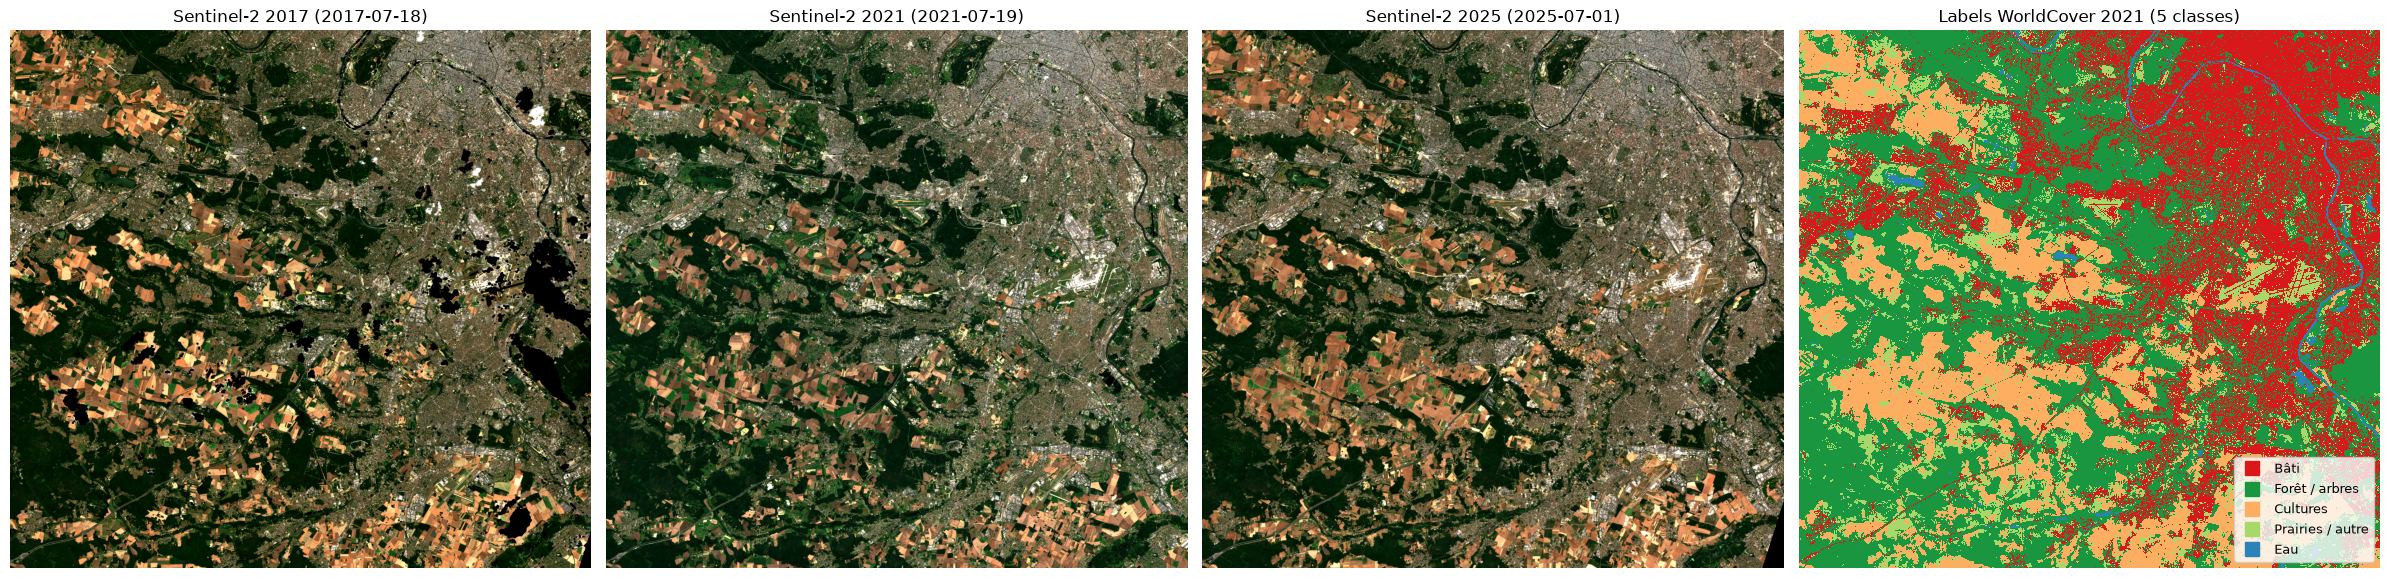

In [17]:
def rgb(chemin, bornes=None):
    with rasterio.open(chemin) as src:
        img = src.read([3, 2, 1]).astype("float32")  # B04, B03, B02 -> rouge, vert, bleu
    img = np.moveaxis(img, 0, -1)
    if bornes is None:
        bornes = np.percentile(img[img > 0], [2, 98])
    return np.clip((img - bornes[0]) / (bornes[1] - bornes[0]), 0, 1), bornes

# Même étirement de contraste pour les trois années : si une image paraît beaucoup plus claire
# ou plus sombre que les autres, c'est un problème de radiométrie à corriger avant d'aller plus loin.
_, bornes = rgb(DATA_DIR / "s2_2021.tif")

couleurs = ListedColormap(["#d7191c", "#1a9641", "#fdae61", "#a6d96a", "#2b83ba"])
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, annee in zip(axes[:3], PERIODES):
    img, _ = rgb(DATA_DIR / f"s2_{annee}.tif", bornes)
    ax.imshow(img)
    ax.set_title(f"Sentinel-2 {annee} ({metadonnees['sentinel2'][annee]['date']})")
    ax.axis("off")

lab = np.ma.masked_equal(labels.values, 255)
axes[3].imshow(lab, cmap=couleurs, vmin=0, vmax=4, interpolation="nearest")
axes[3].set_title("Labels WorldCover 2021 (5 classes)")
axes[3].axis("off")
for i, nom in enumerate(NOMS_CLASSES):
    axes[3].plot([], [], "s", color=couleurs(i), label=nom, markersize=10)
axes[3].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(DATA_DIR / "apercu_donnees.png", dpi=120)
plt.show()

In [18]:
with open(DATA_DIR / "metadonnees.json", "w", encoding="utf-8") as f:
    json.dump(metadonnees, f, indent=2, ensure_ascii=False)
print(json.dumps(metadonnees["sentinel2"], indent=2))

{
  "2017": {
    "date": "2017-07-18",
    "part_invalide": 0.030504183444650737,
    "processing_baseline": 2.12,
    "items": [
      "S2A_MSIL2A_20170718T105651_R094_T31UDQ_20210210T104414",
      "S2A_MSIL2A_20170718T105651_R094_T31UDP_20210210T104349"
    ]
  },
  "2021": {
    "date": "2021-07-19",
    "part_invalide": 0.006980445108866009,
    "processing_baseline": 3.0,
    "items": [
      "S2B_MSIL2A_20210719T104619_R051_T31UDQ_20210719T201900",
      "S2B_MSIL2A_20210719T104619_R051_T31UDP_20210719T205949"
    ]
  },
  "2025": {
    "date": "2025-07-01",
    "part_invalide": 0.0013165191811540038,
    "processing_baseline": 5.11,
    "items": [
      "S2B_MSIL2A_20250701T105619_R094_T31UDQ_20250701T132043",
      "S2B_MSIL2A_20250701T105619_R094_T31UDP_20250701T132043"
    ]
  }
}


## Bilan

Dates retenues : **18/06/2017**, **19/07/2021** et **01/07/2025**, toutes avec moins de 1 % de pixels nuageux sur la zone.

- les 4 couches ont exactement la même grille (EPSG:32631, 10 m)
- visuellement, les couleurs sont cohérentes entre les années après correction de l'offset
- la répartition des classes est plausible : bâti dense au nord-est (Paris et petite couronne), cultures sur les plateaux, forêts dans les vallées

Les dates et identifiants des scènes sont sauvegardés dans `metadonnees.json`.